<a href="https://colab.research.google.com/github/kalinapeterson12/Project-1---Bank-Data-Classification/blob/main/Project_1_Data_201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bank Marketing Evaluation

### Kalina Peterson

# Part 1: Understand Your Problem

### Data Interpretation and Question

 Each row of my dataset is a potential customer for the bank's product: a bank term deposit. My response variable is whether or not the customer will subscribe and deposit their money in the bank. The variable is binary (yes/no).

  My Question: What variables predict whether or not a customer will deposit their money in the bank

Response: Customer subscribes or does not subscribe


 The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict  whether
customer characteristics and campaign information can determine if the client will subscribe to a term deposit (variable y).



### Possible Predictors for Classification

I believe that the following variables may be correlated with our target, though this list is subject to change after loading and exploring the dataset.

 - Duration (the length of the phone call)
 - occupation (more money, more capable of depositing)
 - default (in debt, they probably don't have money to spare)
 - balance (higher balance --> more money to deposit)
 - education (higher education - more income? or more student debt?)
 - Age - money is tighter in your 20s or after youre retired
 - housing - if they currently have a housing loan, they may not be in a position to deposit money



### Distribution of Response Variable (y)

 - **How many observations belong to each class?**
 - **Is the dataset reasonably balanced or imbalanced?**



In [1]:
# Libraries
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
#from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.datasets import load_iris
from sklearn.metrics import mean_squared_error, roc_auc_score
print("libraries loaded!")

libraries loaded!


In [2]:
# Mounting Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Data
bank = pd.read_csv("/content/drive/MyDrive/Data_201/Datasets/bank-full.csv", sep=';')

In [4]:
# Viewing the counts for the target
bank.value_counts('y')

,count
y,
no,39922
yes,5289


In [5]:
# adapting our target as numeric variable (0/1 instead of no/yes)
bank['y_numeric'] = (bank['y'] == 'yes').astype(int) #no=0, yes = 1
print(bank['y_numeric'].value_counts(normalize=True)) #Shows the proportion of each class.

y_numeric
0    0.883015
1    0.116985
Name: proportion, dtype: float64


The dataset's response variable is imbalanced. More consumers choose not to subscribe to the bank deposit program than those who choose to subscribe.

To ensure our model is accurate, I will perform stratification when dividing our data into training and testing groups. This ensures there are results of both types (subscribed and non-subscribed) in our training and test data.

### Defining false positive and false negative in the context of the dataset


**False Positive:** Consumers are predicted to subscribe when, in reality, they opted not to

**False Negative:** Consumers are predicted NOT to subscribe when, in reality, they choose to.

### Error Concerns

In this scenario, false negatives are a greater threat to the bank. False negatives lead to missed financial opportunities where individuals who would've deposited money in the bank were not contacted about the program. This harms the bank through oppurtunity cost, lessening the number of deposits they could've had.

# Part 2: Explore and Prepare the Data


### Examinining the Data & Fixing Missing Values

In [6]:
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,y_numeric
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0


In [8]:
bank.shape

(45211, 18)

In [10]:
# Viewing NA's. There should be some in contact poutcome and pdays,
bank.isnull().sum(),


(age          0
 job          0
 marital      0
 education    0
 default      0
 balance      0
 housing      0
 loan         0
 contact      0
 day          0
 month        0
 duration     0
 campaign     0
 pdays        0
 previous     0
 poutcome     0
 y            0
 y_numeric    0
 dtype: int64,)

Examining the metadata (https://archive.ics.uci.edu/dataset/222/bank+marketing) reveals that NA values do, in fact, exist in pdays and contact variables. The NA's are stored in variables such as "unknown" or "-1" (If the customer had not been previously contacted). The following code fixes NA value classification for contact  and pdays by replacing "unknown" and "-1" values with NA


In [11]:
# Fixing NA values to be identified correctly
bank["contact"] = bank["contact"].replace("unknown", pd.NA)
bank["pdays"] = bank["pdays"].replace(-1, pd.NA)
bank.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,13020
day,0


### Useful Classification Predictors
  I conducted research on each of the variables, what they mean, and how they could affect the target variable. With a better understanding now of the possible predictors, I will visualize and explore the following:

 - Duration - length of the phone call
 - Default - whether or not the customer defaulted
 - Balance - the customers account balance
 - Education - level of education
 - Age - age of the individual
 - Housing - whether or not the individual has a housing loan
 - Month - last contact month of the year
 - Poutcome - outcome with individual previously


   I will only select 2-3 variables for my model, so after visualization this list of variables will significantly decrease.

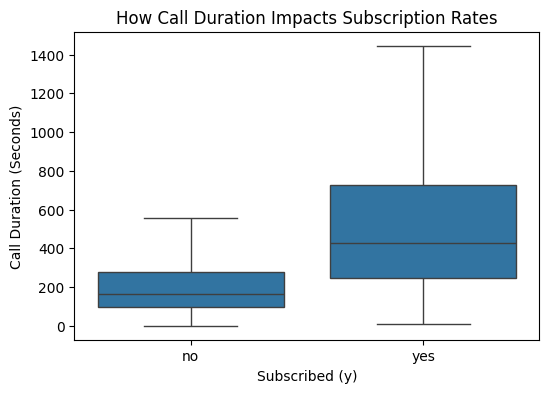

In [12]:
# Visualizing the relationship between Duration and Y
plt.figure(figsize=(6, 4))
sns.boxplot(x='y', y='duration', data=bank, showfliers=False) # Hides outliers for clarity
plt.xlabel("Subscribed (y)")
plt.ylabel("Call Duration (Seconds)")
plt.title("How Call Duration Impacts Subscription Rates")
plt.show()


Duration seems like an important variable, there is not a large amount of overlap in duration for those who said yes to the program and those who didn't. Thus, call duration seems to be positively corelated with whether or not an individual subscribes to the bank's product

<Figure size 600x400 with 0 Axes>

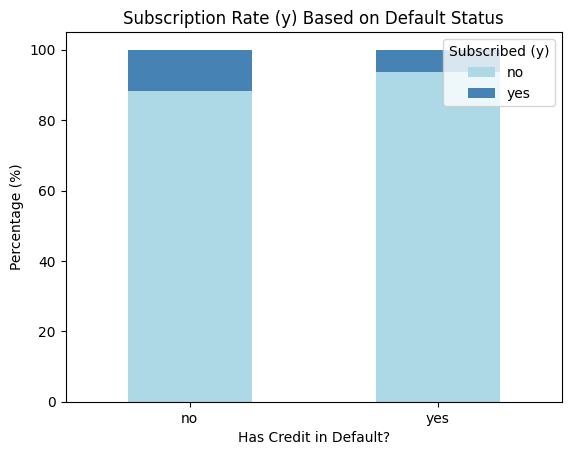

In [13]:
# Visualizing the relationship between Default and Y
plt.figure(figsize=(6, 4))

# Normalize the data by row to show percentages instead of raw counts
cross_tab_pct = pd.crosstab(bank['default'], bank['y'], normalize='index') * 100

# Plot as a stacked bar chart
cross_tab_pct.plot(kind='bar', stacked= True, color=['lightblue', 'steelblue'] )
plt.title("Subscription Rate (y) Based on Default Status")
plt.xlabel("Has Credit in Default?")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Subscribed (y)", loc="upper right")
plt.show()

There doesn't appear to be a huge difference. Those who default definetely have less subscribed than those who do not. That makes logical sense as those who are unable to pay their credit card debt would likely not be investing large amounts of money in the bank.

/tmp/ipykernel_1836/4183833071.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='y', y='balance', data=bank, showfliers=False, palette="Set2")


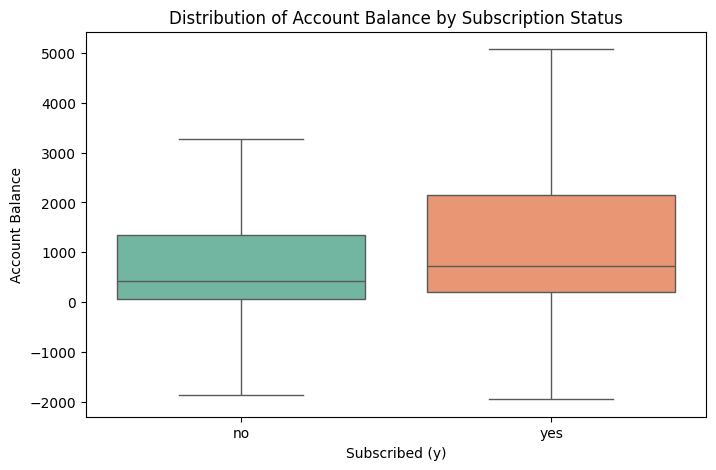

In [14]:
# Visualization of Balance vs Y
plt.figure(figsize=(8, 5))
# showfliers=False cuts out the noise of extreme outliers to let you compare the averages
sns.boxplot(x='y', y='balance', data=bank, showfliers=False, palette="Set2")

plt.xlabel("Subscribed (y)")
plt.ylabel("Account Balance")
plt.title("Distribution of Account Balance by Subscription Status")
plt.show()

It looks like there is a higher median account balance for those who said yes, but there have also been scenarios where people who subscribed to the bank deposit have had a negative account balance. I'm not sure if this will be the strongest predictor for our model.

There is significant overlap between these two groups, so balance is likely not a strong predictor for y.

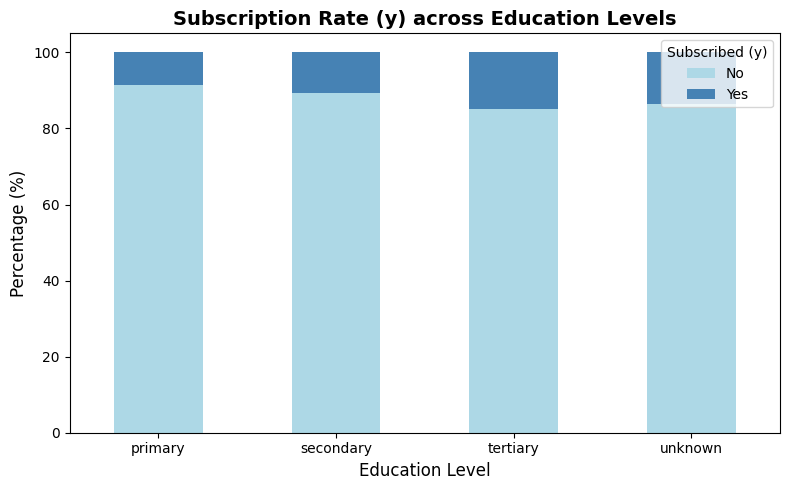

In [15]:
# Education vs Y
# 1. Create a cross-tabulation showing the percentage split within each education level
education_pct = pd.crosstab(bank['education'], bank['y'], normalize='index') * 100

# 2. Plot the 100% stacked bar chart
plt.figure(figsize=(8, 5))
education_pct.plot(kind='bar', stacked=True, color=['lightblue', 'steelblue'], ax=plt.gca())

# 3. Format the graph labels and titles
plt.title("Subscription Rate (y) across Education Levels", fontsize=14, fontweight='bold')
plt.xlabel("Education Level", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.xticks(rotation=0) # Keeps the tier names horizontal and easy to read
plt.legend(title="Subscribed (y)", labels=['No', 'Yes'], loc="upper right")

# 4. Clean up layout and display
plt.tight_layout()
plt.show()

In [16]:
bank.value_counts('education')

,count
education,
secondary,23202
tertiary,13301
primary,6851
unknown,1857


It does look like there is a correlation between a higher level of education and whether or not a consumer is likely to subscribe to the bank's program. However, this variable has unknown values that may make classification difficult

/tmp/ipykernel_1836/147632097.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='y', y='age', data=bank, showfliers=False, palette="Set2")


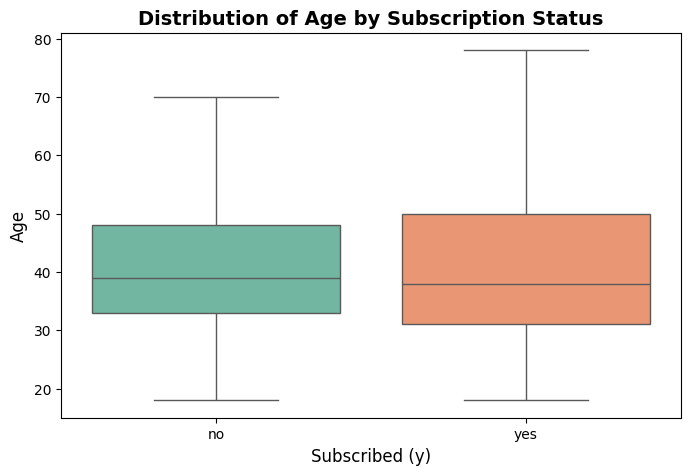

In [17]:
# Age vs Y
# Set up the figure size
plt.figure(figsize=(8, 5))

# Plot age distribution across subscription status (hiding outliers to focus on the main trends)
sns.boxplot(x='y', y='age', data=bank, showfliers=False, palette="Set2")

# Format labels and title
plt.xlabel("Subscribed (y)", fontsize=12)
plt.ylabel("Age", fontsize=12)
plt.title("Distribution of Age by Subscription Status", fontsize=14, fontweight='bold')

# Display the plot
plt.show()

Extreme amount of overlap between subscription and non subscription groups. Age does not seem to be a significant factor

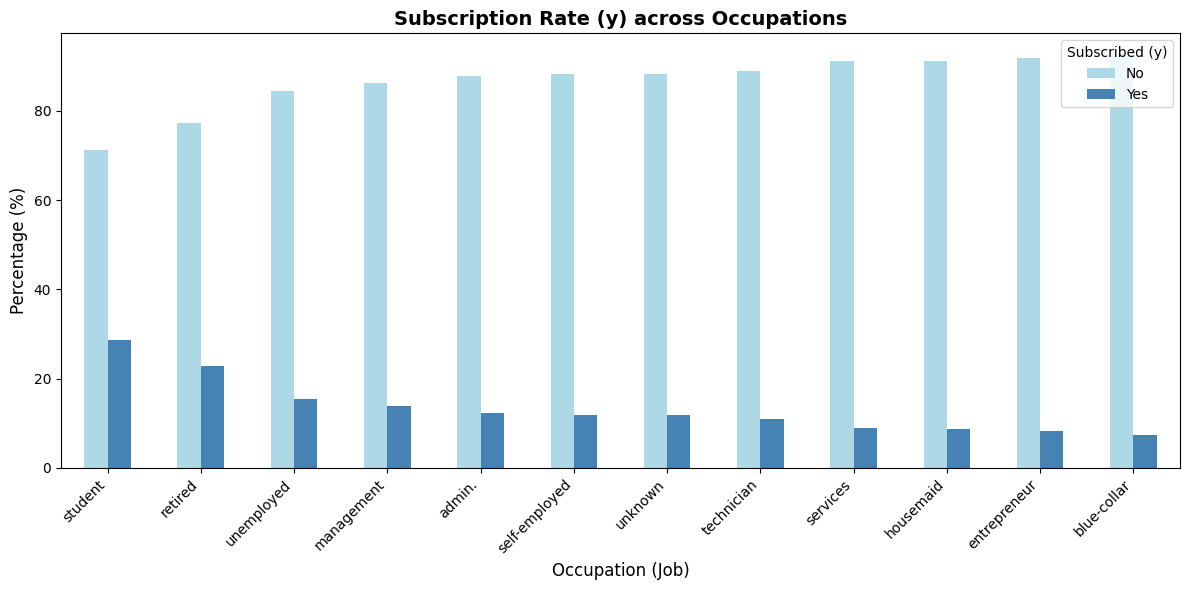

In [18]:
# Job vs Y
# 1. Create a cross-tabulation showing the percentage split within each occupation
job_pct = pd.crosstab(bank['job'], bank['y'], normalize='index') * 100

# 2. Sort by subscription rate (yes) so the most successful jobs float to the top
job_pct = job_pct.sort_values(by='yes', ascending=False)

# 3. Plot the chart
plt.figure(figsize=(12, 6))
job_pct.plot(kind='bar', stacked= False, color=['lightblue', 'steelblue'], ax=plt.gca())

plt.title("Subscription Rate (y) across Occupations", fontsize=14, fontweight='bold')
plt.xlabel("Occupation (Job)", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.xticks(rotation=45, ha='right') # Rotates long job titles so they don't overlap
plt.legend(title="Subscribed (y)", labels=['No', 'Yes'], loc="upper right")

plt.tight_layout()
plt.show()

Students and retired indivisuals are far more likely to say yes, which is surprising to me. Occupation could be an important factor

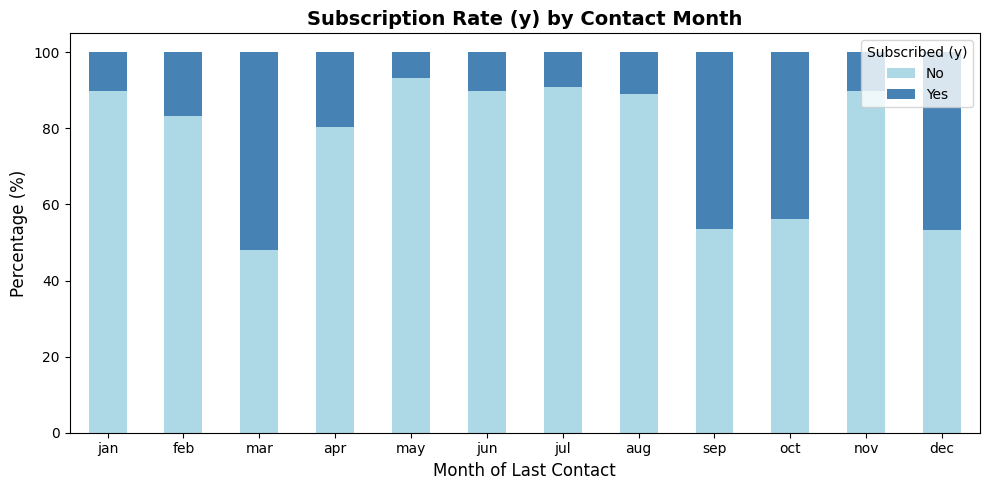

In [19]:
# Month vs Y
# 1. Create the cross-tabulation percentage split
month_pct = pd.crosstab(bank['month'], bank['y'], normalize='index') * 100

# 2. Chronologically order the months so it reads left-to-right (Jan to Dec)
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
# Reindex ensures it only includes months present in your data, in calendar order
month_pct = month_pct.reindex([m for m in month_order if m in month_pct.index])

# 3. Plot the chart
plt.figure(figsize=(10, 5))
month_pct.plot(kind='bar', stacked=True, color=['lightblue', 'steelblue'], ax=plt.gca())

# 4. Format the graph
plt.title("Subscription Rate (y) by Contact Month", fontsize=14, fontweight='bold')
plt.xlabel("Month of Last Contact", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Subscribed (y)", labels=['No', 'Yes'], loc="upper right")

plt.tight_layout()
plt.show()



Month seems to have a very strong correlation with y. Some months have up to 50% of consumers contacted opting to subscribe to the bank's deposit program.

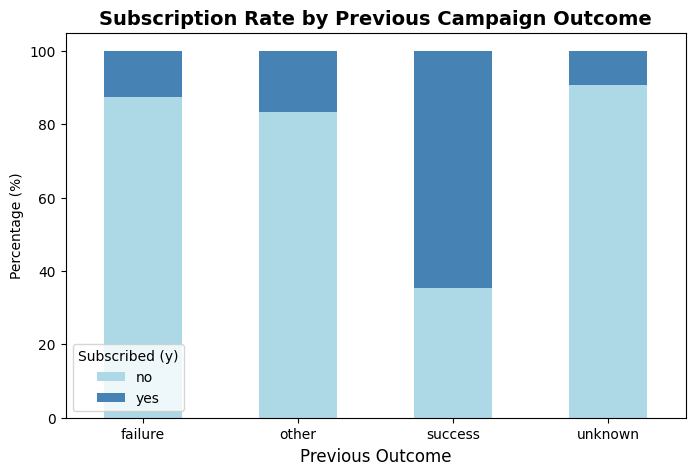

In [20]:
# Poutcome vs Y
poutcome_pct = pd.crosstab(bank['poutcome'], bank['y'], normalize='index') * 100

plt.figure(figsize=(8, 5))
poutcome_pct.plot(kind='bar', stacked=True, color=['lightblue', 'steelblue'], ax=plt.gca())
plt.title("Subscription Rate by Previous Campaign Outcome", fontsize=14, fontweight='bold')
plt.xlabel("Previous Outcome", fontsize=12)
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Subscribed (y)")
plt.show()


Poutcome has a strong correlation with y. Previous success with a customer subscribing is a large indicator of whether or not they will subscribe to the program again.

**Summary of Visualization Findings**

 - *Duration - strongly correlated with y. Will use in the model*
 - *job - possible correlations with some occupations*
 - default - possible correlation, not very strong difference between groups
 - balance - lots of overlap between groups, likely not the strongest
 - education - higher education -> more likely. However, too many missing values
 - Age - no strong correlation
 - housing - possible correlation, not a strong difference between groups
 - *Month - Strong correlation with y. Will use in model*
 - *Poutcome - strong correlation with y. Will use in model*

 **Final Model Predictors:** Duration, Month, & Poutcome

### Encoding Categorical Predictors

Month and Poutcome are both categorical and need to be stored as numeric values


In [21]:
# Adapting month with ordinal encoding
    # one hot encoding would be better, but I don't have time for this project specifically
bank["month_numeric"] = bank["month"].map({
    'jan': 1,
    'feb': 2,
    'mar': 3,
    'apr': 4,
    'may': 5,
    'jun': 6,
    'jul': 7,
    'aug': 8,
    'sep': 9,
    'oct': 10,
    'nov': 11,
    'dec': 12
})

In [22]:
# adapting poutcome with ordinal encoding
    # one hot encoding would be better, but I don't have the time for this project
bank["poutcome_numeric"] = bank["poutcome"].map({
    'failure': 0,
    'other': 1,
    'unknown': 2,
    'success': 3
})

In [23]:
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,y_numeric,month_numeric,poutcome_numeric
0,58,management,married,tertiary,no,2143,yes,no,<NA>,5,may,261,1,<NA>,0,unknown,no,0,5,2
1,44,technician,single,secondary,no,29,yes,no,<NA>,5,may,151,1,<NA>,0,unknown,no,0,5,2
2,33,entrepreneur,married,secondary,no,2,yes,yes,<NA>,5,may,76,1,<NA>,0,unknown,no,0,5,2
3,47,blue-collar,married,unknown,no,1506,yes,no,<NA>,5,may,92,1,<NA>,0,unknown,no,0,5,2
4,33,unknown,single,unknown,no,1,no,no,<NA>,5,may,198,1,<NA>,0,unknown,no,0,5,2


### Splitting Data & Cross Validation

In [24]:
#set features (predictors) and target
X = bank[['duration', 'poutcome_numeric', 'month_numeric']]
y = bank['y']

# Split the data into training and final test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25, #75% and 25%
    stratify=y,   #keeps the proportion of default/non-default cases similar
    random_state= 42  #makes the split reproducible
    )

In [25]:
# Cross Validation
# -----------------------------
# KNN: tune k and weights
# -----------------------------

knn = make_pipeline(
    StandardScaler(), #scaling the data first
    KNeighborsClassifier() # then classifying it --> Knn is the classifier
)

knn_grid = {
    'kneighborsclassifier__n_neighbors': [1, 3, 5, 11, 21, 51], #each of the ks we want to test (to find the most effective)
    'kneighborsclassifier__weights': ['uniform', 'distance']  # different weight methods (does distance from target matter?) we want to try
}

        # We now have 12 different cominations of weights and ks. Which works best?

grid_knn = GridSearchCV(
    knn, # <-- passes the data through the pipeline
    knn_grid, # <- as it passes through it tests k and weight 5 times
    cv=5, # split into five folds
    scoring='roc_auc' # gives score for each fold, picks the best one
)

grid_knn.fit(X_train, y_train) # fits the best combination with all the training data


# -----------------------------
# Logistic Regression: tune C
# -----------------------------

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

logreg_grid = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    logreg,
    logreg_grid,
    cv=5,
    scoring='roc_auc'
)

grid_lr.fit(X_train, y_train)


# -----------------------------
# LDA: evaluate with CV
# -----------------------------

lda = LinearDiscriminantAnalysis()

lda_scores = cross_val_score(
    lda,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)


# -----------------------------
# QDA: evaluate with CV
# -----------------------------

qda = QuadraticDiscriminantAnalysis()

qda_scores = cross_val_score(
    qda,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)


# -----------------------------
# Compare results
# -----------------------------

print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC-AUC:", round(grid_knn.best_score_, 4))

print("\nLogistic Regression best parameters:", grid_lr.best_params_)
print("Logistic Regression best CV ROC-AUC:", round(grid_lr.best_score_, 4))

print("\nLDA mean CV ROC-AUC:", round(lda_scores.mean(), 4))
print(lda_scores.mean())

print("QDA mean CV ROC-AUC:", round(qda_scores.mean(), 4))
print(qda_scores.mean())


KNN best parameters: {'kneighborsclassifier__n_neighbors': 51, 'kneighborsclassifier__weights': 'uniform'}
KNN best CV ROC-AUC: 0.8901

Logistic Regression best parameters: {'logisticregression__C': 0.001}
Logistic Regression best CV ROC-AUC: 0.8043

LDA mean CV ROC-AUC: 0.8089
0.8088965114336274
QDA mean CV ROC-AUC: 0.8321
0.8320735477428199


Here, KNN has the highest ROC-AUC score of 0.8901. However, the best k value was also the highest one provided. I need to experiement with different k values before declaring the best combination of weight and k. I will do that during Part 3: Building the classifiers

# Part 3: Building the Classifiers

### Logistic Regresssion

In the previous code chunk the best c value for the Logistic regression was 0.001, so that is the value we will use with our final model

In [26]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(random_state=42)

logreg.fit(X_train, y_train)


LogisticRegression(random_state=42)

The fitted model has the form:

$$ z=\beta_0+\beta_1X $$

where:

- $\beta_0$ is the intercept
- $\beta_1$ is the coefficient for balance
- X is the customer's credit card balance

Let's inspect the values learned by the model.

In [27]:
# Find intercept and coefficents
beta_0 = logreg.intercept_[0]
beta_duration = logreg.coef_[0][0]  # scaled duration
beta_poutcome = logreg.coef_[0][1]    # scaled poutcome
beta_month = logreg.coef_[0][2]    # scaled month

# Print results
print("Intercept:", beta_0)
print("Duration:", beta_duration)
print("Poutcome:", beta_poutcome)
print("Month:", beta_month)



Intercept: -3.9983229811342476
Duration: 0.0035691245482139637
Poutcome: 0.3305574706799018
Month: 0.02930295134294589


Logistic Model Equation:

$$ z=-3.998 + 0.0036(seconds) + 0.3206(poutcome) + 0.0293(month) $$

The coefficents for each of these variables are positive, meaning each of them are positively corrleated with y. In terms of our situation, that means that **if the duration of the call increases, the call takes place later in the year, or if the previous outcome was sucessful, the probability that someone will subscribe to the bank's program increases.**

**Predicted Probabilities**

In [28]:
prob_deposit = logreg.predict_proba(X_test)[:, 1]
prob_deposit


array([0.07009302, 0.03636061, 0.09102104, ..., 0.09184824, 0.166361  ,
       0.05278407])

In [29]:
#obtain the model's class predictions

pred_50 = logreg.predict(X_test)

In [30]:
#Create a table to compare the results
results = X_test.copy()

results["Actual"] = y_test.values
results["P(Deposit)"] = prob_deposit
results["Prediction_0.50"] = pred_50

results.head(15)

,duration,poutcome_numeric,month_numeric,Actual,P(Deposit),Prediction_0.50
22684,145,2,8,no,0.070093,no
30384,93,1,2,no,0.036361,no
10483,241,2,6,no,0.091021,no
8732,109,2,6,no,0.058836,no
21614,188,2,8,no,0.080781,no
16411,698,2,7,no,0.345057,no
18514,158,2,7,no,0.071216,no
34618,200,1,5,no,0.056924,no
10745,69,2,6,no,0.051411,no
30237,588,0,2,no,0.136925,no


**Changing the Threshold to 20%**

In this scenario, we want to minimize the oppurtunity cost of false negatives. We can risk reaching out to more people that aren't interested if it means we contact the individuals who are willing and interested in subscribing to the bank's program and depositing their money. We want to minimize situations like observation 34210, where the indvidual would've actually subscribed, but was not contacted.

In [31]:
# Lower the threshold to 0.20.

results["Prediction_0.20"] = np.where(
    results["P(Deposit)"] >= 0.20, "yes", "no")

results.head()


,duration,poutcome_numeric,month_numeric,Actual,P(Deposit),Prediction_0.50,Prediction_0.20
22684,145,2,8,no,0.070093,no,no
30384,93,1,2,no,0.036361,no,no
10483,241,2,6,no,0.091021,no,no
8732,109,2,6,no,0.058836,no,no
21614,188,2,8,no,0.080781,no,no


### LDA Fit & Test Predictions


In [32]:
#Create model
lda = LinearDiscriminantAnalysis()

#Fit the model
lda.fit(X_train, y_train)

#Make prediction
lda_pred = lda.predict(X_test)

In [33]:
#Get predicted probabilities on the unseen test set
lda.classes_

#get the probability of defaulting "Yes"
prob_yes_lda = lda.predict_proba(X_test)[:, 1]

prob_yes_lda[:10]

array([0.03677432, 0.01739392, 0.05829138, 0.02831994, 0.0465251 ,
       0.46450172, 0.03828787, 0.0346665 , 0.02267163, 0.18426021])

## QDA


In [34]:
#Create model
qda = QuadraticDiscriminantAnalysis()

#Fit the model
qda.fit(X_train, y_train)

#Make prediction
qda_pred = qda.predict(X_test)

In [35]:
#Get predicted probabilities on the unseen test set
qda.classes_

#get the probability of defaulting "Yes"
prob_yes_qda = qda.predict_proba(X_test)[:, 1]

prob_yes_qda[:10]

array([0.03374066, 0.03741423, 0.03531517, 0.03034811, 0.03539563,
       0.40058425, 0.03175147, 0.0322512 , 0.03068866, 0.38891926])

## KNN

In [36]:
# Tuning the k value
knn_grid = {
    'kneighborsclassifier__n_neighbors': [ 71, 91, 111, 131, 151, 171, 201], #each of the ks we want to test (to find the most effective)
    'kneighborsclassifier__weights': ['uniform', 'distance']  # different weight methods (does distance from target matter?) we want to try
}

        # We now have 14 different cominations of weights and ks. Which works best?

grid_knn = GridSearchCV( #
    knn, # <-- passes the data through the pipeline
    knn_grid, # <- as it passes through it tests k and weight 5 times
    cv=5, # split into five folds
    scoring='roc_auc' # gives score for each fold, picks the best one
)

grid_knn.fit(X_train, y_train) # fits the best combination with all the training data

print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC-AUC:", round(grid_knn.best_score_, 4))


KNN best parameters: {'kneighborsclassifier__n_neighbors': 111, 'kneighborsclassifier__weights': 'uniform'}
KNN best CV ROC-AUC: 0.8937


The best k value was 171, a larger k increases bias slightly but drastically reduces variance. Smaller k values (like 3 or 5) captured too much local noise, leading to overfitting. Uniform was the best weight method. This combination of Uniform and k = 171 yielded a ROC-AUC score of 0.892.



**K-Value Cross Validation Performance Visualization**

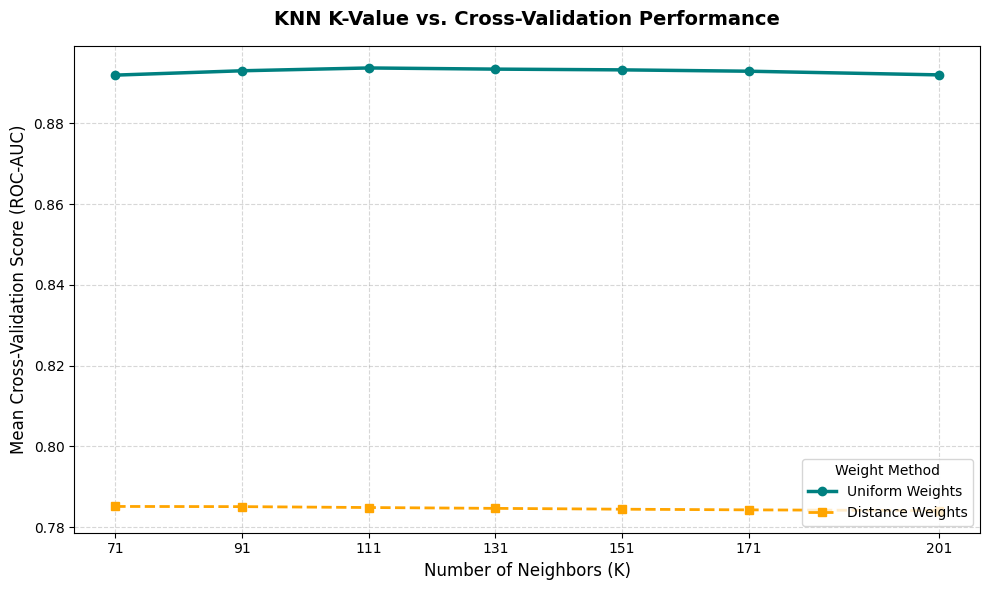

In [37]:
# I used Google Gemini to help generate this code. The class code only applied to polynomial models.
# I discussed this code with Professer Alraee and got permission

# 1. Convert the cross-validation results into a clean Pandas DataFrame
cv_results = pd.DataFrame(grid_knn.cv_results_)

# 2. Separate the results into 'uniform' vs 'distance' weights
uniform_data = cv_results[cv_results['param_kneighborsclassifier__weights'] == 'uniform']
distance_data = cv_results[cv_results['param_kneighborsclassifier__weights'] == 'distance']

# 3. Pull out your X (K values) and Y (Mean CV performance scores) data points
k_uniform = uniform_data['param_kneighborsclassifier__n_neighbors']
scores_uniform = uniform_data['mean_test_score']

k_distance = distance_data['param_kneighborsclassifier__n_neighbors']
scores_distance = distance_data['mean_test_score']

# 4. Generate the line graph
plt.figure(figsize=(10, 6))

# Plot Uniform Weights line
plt.plot(k_uniform, scores_uniform, marker='o', linestyle='-', color='teal', linewidth=2.5, label='Uniform Weights')

# Plot Distance Weights line
plt.plot(k_distance, scores_distance, marker='s', linestyle='--', color='orange', linewidth=2, label='Distance Weights')

# 5. Format labels, grid, and title to look polished for submission
plt.title('KNN K-Value vs. Cross-Validation Performance', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Neighbors (K)', fontsize=12)
plt.ylabel('Mean Cross-Validation Score (ROC-AUC)', fontsize=12)
plt.xticks(list(k_uniform)) # Forces the X-axis to display your exact K values (71, 91, etc.)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Weight Method", loc='lower right', fontsize=10)

# Display the plot
plt.tight_layout()
plt.show()


When it comes to k values, the highest performing k's were 171, 151, and 201. Ultimately, 171, had the highest score, but the larger k value helped prevent confusion from noise in the data. we can see the model's ROC and AUC increased as k increased.

## Standardization

For this dataset, I opted to standardize my predictors in the earlier chunks of code. There is a large difference in how my predictors are measured. Duration, measured in seconds, goes into the thousands. Meanwhile, poutcome only has values ranging from 1-4 and month only has values ranging from 1-12. To prevent month and poutcome from being drowned out, the predictors were standardized.

# Part 4: Evaluate Your Models

## Choosing a Threshold

Because I want to minimize the amount of false negatives (opportunity costs) for the bank, I need to lower my threshold to ensure that no customers who would subscribe to the bank are passed over. Though there are consequences, such as raising the amount of false positives, there are no serious reprecussions for false positives. (Contact and advertising take slightly longer to ensure outreach to more possible customers)

So, I will be operating under a **20% Threshold** rather than 50%.

## Logistic Regression

**Confusion Matrix & Scores with 20% Threshold**

In [38]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix

print("\n 20% Threshold Confusion Matrix \n")
confusion_matrix(
    results["Actual"],
    results["Prediction_0.20"]
)


 20% Threshold Confusion Matrix 



array([[9222,  759],
       [ 767,  555]])

For binary classification, the matrix represents:
|                |   Predicted No |  Predicted Yes |
| -------------- | -------------: | -------------: |
| **Actual No**  |  True Negative | False Positive |
| **Actual Yes** | False Negative |  True Positive |

In [39]:
# Accuracy = TP + TN/ TP + TN + FP + FN
accuracy = (9222+555)/(555+9222+759+767)
print('Logistic Model Accuracy:', accuracy)

# Precision = TP/(TP + FP)
precision = 555/(555+759)
print('Logistic Model Precision:', precision)

# Recall = TP/(TP + FN)
recall = 555/(555+767)
print('Logistic Model Recall:', recall)

# Specificity = TN/(TN + FP)
specificity = 9222/(9222+759)
print('Logistic Model Specificity:', specificity)
# F1 Score
f1 =  (2*precision*recall)/(precision + recall)
print('Logistic Model F1 Score:', f1)

# ROC-AUC Score (found earlier)
print("Logistic Model ROC-AUC: 0.8043")

Logistic Model Accuracy: 0.8649915951517296
Logistic Model Precision: 0.4223744292237443
Logistic Model Recall: 0.4198184568835098
Logistic Model Specificity: 0.9239555154794109
Logistic Model F1 Score: 0.421092564491654
Logistic Model ROC-AUC: 0.8043


## LDA

In [40]:
# Evaluating the Model
# ----------------------
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

print(accuracy_score(y_test, lda_pred))
print(confusion_matrix(y_test, lda_pred,  labels=["no", "yes"]))

0.8854286472617889
[[9710  271]
 [1024  298]]


LDA has a very high amount of true negatives, but also has a very large number of FALSE negatives. In the context of this dataset, that 1004 people were predicted not to subscribe to the bank's deposit program. This is a huge oppurtunity cost for the bank and makes this model a poor option for classification.

**Lowering the Threshold to 20%**

Again, I am going to lower the classification threshold from 0.5 to 0.2 to improve the model in the bank's context.

In [41]:
# We never altered the threshold for LDA, and I wasn't sure how to adapt the code. Google Gemini helped with the code below
from sklearn.metrics import confusion_matrix

# 1. Get the raw probability of 'yes' (class 1) from your fitted LDA model
# (Ensure your lda model was previously fitted using lda.fit(X_train, y_train))
lda_probs = lda.predict_proba(X_test)[:, 1]

# 2. Enforce your custom 0.20 decision boundary (predicting text strings directly)
lda_pred_020 = np.where(lda_probs >= 0.20, "yes", "no")

# 3. Print the new confusion matrix to evaluate the fix
# (Assuming your y_test labels match your text strings "yes"/"no")
cm_lda_020 = confusion_matrix(y_test, lda_pred_020, labels=["no", "yes"])

print("=== LDA Confusion Matrix at 0.20 Threshold ===")
print(cm_lda_020)


=== LDA Confusion Matrix at 0.20 Threshold ===
[[9170  811]
 [ 756  566]]


Now LDA is a better option than before. The amount of false negatives has significantly decreased. Now I can calculate accuracy, recall, and F1 scores for LDA

For binary classification, the matrix represents:
|                |   Predicted No |  Predicted Yes |
| -------------- | -------------: | -------------: |
| **Actual No**  |  True Negative | False Positive |
| **Actual Yes** | False Negative |  True Positive |

In [42]:
# Accuracy = TP + TN/ TP + TN + FP + FN
accuracy = (9170+566)/(566+9170+811+756)
print('LDA Model Accuracy:', accuracy)

# Precision = TP/(TP + FP)
precision = 566/(566+811)
print('LDA Model Precision:', precision)

# Recall = TP/(TP + FN)
recall = 566/(566+756)
print('LDA Model Recall:', recall)

# Specificity = TN/(TN + FP)
specificity = 9170/(9170+811)
print('LDA Model Specificity:', specificity)
# F1 Score
f1 =  (2*precision*recall)/(precision + recall)
print('LDA Model F1 Score:', f1)

# ROC-AUC Score (found earlier)
print("LDA Model ROC-AUC: 0.8089")

LDA Model Accuracy: 0.8613642395824117
LDA Model Precision: 0.41103848946986205
LDA Model Recall: 0.4281391830559758
LDA Model Specificity: 0.9187456166716762
LDA Model F1 Score: 0.419414597999259
LDA Model ROC-AUC: 0.8089


## QDA

In [43]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)
print(accuracy_score(y_test, qda_pred))
print(confusion_matrix(y_test, qda_pred,  labels=["no", "yes"]))

0.8849862868265063
[[9681  300]
 [1000  322]]


**Lowering the Classification Threshold to 20%**

Again, like other models, QDA has a large amount of false negatives, which is not ideal for the bank. To prevent false negatives, the threshold will be lowered from 0.50 to 0.20

In [44]:
# Altering the LDA code for QDA purposes
from sklearn.metrics import confusion_matrix

# 1. Get the raw probability of 'yes' (class 1) from the fitted QDA model
qda_probs = qda.predict_proba(X_test)[:, 1]

# 2. Apply the 0.20 decision boundary (predicting text strings directly)
qda_pred_020 = np.where(qda_probs >= 0.20, "yes", "no")

# 3. Print the new confusion matrix to evaluate the fix
cm_qda_020 = confusion_matrix(y_test, qda_pred_020, labels=["no", "yes"])

print("=== QDA Confusion Matrix at 0.20 Threshold ===")
print(cm_qda_020)


=== QDA Confusion Matrix at 0.20 Threshold ===
[[9274  707]
 [ 789  533]]


This improves the QDA model. However, It still has more false negatives than both Logistic and LDA models. The amount of true positives and true negatives are good.


**QDA Evaluation Scores**

For binary classification, the matrix represents:
|                |   Predicted No |  Predicted Yes |
| -------------- | -------------: | -------------: |
| **Actual No**  |  True Negative | False Positive |
| **Actual Yes** | False Negative |  True Positive |

In [45]:
# Accuracy = TP + TN/ TP + TN + FP + FN
accuracy = (9274+533)/(533+9274+707+789)
print('QDA Model Accuracy:', accuracy)

# Precision = TP/(TP + FP)
precision = 533/(533+707)
print('QDA Model Precision:', precision)

# Recall = TP/(TP + FN)
recall = 533/(533+789)
print('QDA Model Recall:', recall)

# Specificity = TN/(TN + FP)
specificity = 9274/(9274+707)
print('QDA Model Specificity:', specificity)
# F1 Score
f1 =  (2*precision*recall)/(precision + recall)
print('QDA Model F1 Score:', f1)

# ROC-AUC Score (found earlier)
print("QDA Model ROC-AUC: 0.8321")

QDA Model Accuracy: 0.8676457577634257
QDA Model Precision: 0.42983870967741933
QDA Model Recall: 0.4031770045385779
QDA Model Specificity: 0.9291654142871456
QDA Model F1 Score: 0.4160811865729898
QDA Model ROC-AUC: 0.8321


## KNN

**Confusion Matrix with 20% Threshold**

In [46]:
# 1. Get the raw predicted probabilities for the test data using your optimized grid search
# [:, 1] isolates the probability of the customer subscribing ("yes")
knn_probs = grid_knn.predict_proba(X_test)[:, 1]

# 2. Enforce your optimized 0.20 decision threshold to minimize False Negatives
knn_preds_020 = np.where(knn_probs >= 0.20, "yes", "no")

# 3. Calculate the confusion matrix
# (Ensuring labels match your text strings "no"/"yes")
cm_knn = confusion_matrix(y_test, knn_preds_020, labels=["no", "yes"])

print("=== KNN Confusion Matrix (0.20 Threshold) ===")
print(cm_knn)


=== KNN Confusion Matrix (0.20 Threshold) ===
[[8812 1169]
 [ 372  950]]


For binary classification, the matrix represents:
|                |   Predicted No |  Predicted Yes |
| -------------- | -------------: | -------------: |
| **Actual No**  |  True Negative | False Positive |
| **Actual Yes** | False Negative |  True Positive |

In [47]:
# Accuracy = TP + TN/ TP + TN + FP + FN
accuracy = (8812+950)/(950+8812+1169+372)
print('KNN Model Accuracy:', accuracy)

# Precision = TP/(TP + FP)
precision = 950/(950+1169)
print('KNN Model Precision:', precision)

# Recall = TP/(TP + FN)
recall = 950/(950+372)
print('KNN Model Recall:', recall)

# Specificity = TN/(TN + FP)
specificity = 8812/(8812+1169)
print('KNN Model Specificity:', specificity)
# F1 Score
f1 =  (2*precision*recall)/(precision + recall)
print('KNN Model F1 Score:', f1)

# ROC-AUC Score (found earlier)
print("KNN Model ROC-AUC: 0.8937")

KNN Model Accuracy: 0.8636645138458816
KNN Model Precision: 0.4483246814535158
KNN Model Recall: 0.7186081694402421
KNN Model Specificity: 0.8828774671876566
KNN Model F1 Score: 0.5521650682941006
KNN Model ROC-AUC: 0.8937


## Comparing Models




|      **Model**          |   **Accuracy** |  **Precision** |  **Recall** | **Specificity**  |  **F1 Score**   |  **ROC-AUC**  |
| -------------- | -------------: | -------------: | -------------: |-------------: |-------------: |-------------: |
| Logistic  | 0.864 | 0.422 | 0.419 | 0.924 | 0.421 | 0.804 |
| LDA | 0.861 | 0.411 | 0.428 | 0.919 | 0.419 | 0.809 |
| QDA | **0.867** | 0.430 | 0.403 | **0.929** | 0.416 | 0.832 |
| KNN | 0.863 | **0.448** | **0.718** | 0.883 | **0.552** | **0.894** |

# Part 5: Reflect


Again, false negatives are a greater threat to the bank. False negatives lead to missed financial opportunities where individuals who would've deposited money in the bank were not contacted about the oppurtunity. This harms the bank and lessens the amount of funds and deposits they could've had.

In this scenario, I want high scores in each of these three metrics:
 - Recall - a high recall means the model successfully catches the people who want to subscribe and avoids false negatives
 - ROC-AUC Score - measures the ability of the model to sort into categories. A score of 0.5 means the model is sorting at random
 - F1 Score - a higher score means the model is good at catching those who want to subscribe, while not contacting every possible customer

The other metrics (accuracy, specificity, and precision) are useful, but not as meaningful for the bank's classification problem.


With this in mind, the ideal model for classification is **KNN**. KNN has the highest scores in Recall, ROC-AUC, and F1 making it the best classification model in this particular scenario.

# Part 6: ROC and AUC

/tmp/ipykernel_1836/1096819819.py:47: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="lower right", fontsize=11)


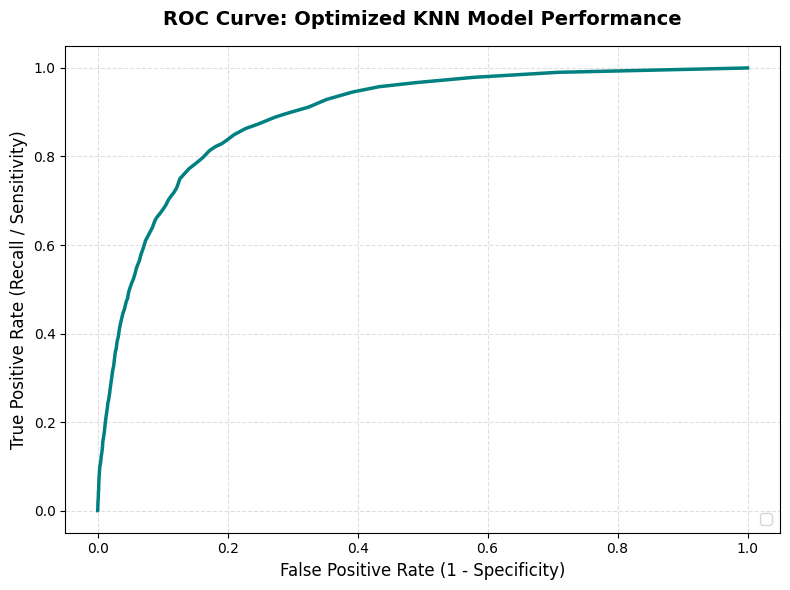

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np

# 1. Convert the response to 0/1 (Fixed: Use lowercase "yes" to match your dataset)
y_test_binary = np.where(
    y_test == "yes",
    1,
    0
)

# 2. Get the probabilities from your optimized KNN model
# (Ensure you ran: knn_probs = grid_knn.predict_proba(X_test)[:, 1] right before this)
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    knn_probs
)

# 3. Calculate the exact test AUC-ROC score to display in the legend
knn_auc = roc_auc_score(y_test_binary, knn_probs)

# 4. Generate the plot
plt.figure(figsize=(8, 6))

# Plot the KNN ROC Curve line and add its score label
plt.plot(
    fpr,
    tpr,
    color='teal',
    linewidth=2.5
)

# Plot the baseline diagonal reference line (Random Guessing)
plt.plot(

    color='grey',
    linestyle="--",
    linewidth=1.5,
    label='Random Guessing (AUC = 0.50)'
)

# 5. Format labels and titles for your final presentation report
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=12)
plt.title("ROC Curve: Optimized KNN Model Performance", fontsize=14, fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc="lower right", fontsize=11)

# Display the final graph
plt.tight_layout()
plt.show()


This graph visually displays the difference between my model and randomly guessing (which would be represented as a diagonal line). The further this line curves towards the top left corner, the better it is at classifying objects into categories.

Here the KNN model is significantly better than randomly guessing which customers would or would not subscribe to the program and deposit their money in the bank

In [49]:
# AUC-ROC score for KNN
auc = roc_auc_score(
    y_test_binary,
    knn_probs
)

print("KNN Test AUC:", auc)


KNN Test AUC: 0.8940279647821026


The AUC-ROC score shows numerically how accurate the model is at identifying whether or not a customer will subscribe to the bank's program, independent of the threshold selected for the model (0.20). The KNN model has a 89.4% chance of correctly classifying the client's subscription choice.

# Part 7: Final Analysis


 Many different machine learning models can be used to predict whether or not a client will subscribe to the bank's deposit program. I tested the bank data on four of these models: Logistic, LDA, QDA, and KNN.

Below is a table showing each of the model scores. The highest score in each category is bolded.




|      **Model**          |   **Accuracy** |  **Precision** |  **Recall** | **Specificity**  |  **F1 Score**   |  **ROC-AUC**  |
| -------------- | -------------: | -------------: | -------------: |-------------: |-------------: |-------------: |
| Logistic  | 0.864 | 0.422 | 0.419 | 0.924 | 0.421 | 0.804 |
| LDA | 0.861 | 0.411 | 0.428 | 0.919 | 0.419 | 0.809 |
| QDA | **0.867** | 0.430 | 0.403 | **0.929** | 0.416 | 0.832 |
| KNN | 0.863 | **0.448** | **0.718** | 0.883 | **0.552** | **0.894** |



 - Accuracy - Not as applicable because of the imbalance in the data (more don't subscribe than subscribe)
 - Precision - model's ability to accurately identify those who would subscribe
 - Recall - model's ability to catch as many potential subscribers as possible of those who are interested
 -  Specificity - the model's efficency at deciding who NOT to contact about the program (non-subscribing individuals)
 - F1 Score - measures the balance between capturing interested customers and ensuring the call list isn't filled with uninterested people
 - ROC-AUC - ability to distinguish between subscribers and non-subscribers (across all thresholds)

In this scenario, we want to catch as many customers as possible, and any machine learning model that overlooks customers willing to subscribe (false negatives) creates a major oppurtunity cost for the bank. So, we want a model with a higher recall score (less false negatives). Of the four models, KNN had the highest recall score of 0.718. KNN also had the highest precision (0.448), F1 Score (0.552) and ROC-AUC score (0.894), which measures the model's ability to classify whether or not a customer would subscribe independent of the selected threshold. With this model, errors are more common in contacting people who aren't interested, than missing those who are.

One limitation of this model is that the duration variable, which is a strong predictor for whether or not someone subscribes, cannot be used to make a call list (as the information can be gathered only after contact is made and whether the custome will subscribe is decided).

Before this model is used in the real world, I would like more information on which variable levels specifically contribute to whether or not the patient subscribes. (Does one month matter more than others, or is a singular previous outcome a stronger predictor?). I would like to use one-hot encoding to find this information, but am unable to due to time constraints. However, the current model shows that duration, month and previous outcome all are strongly associated with whether or not a customer subscribes.

